# The projectiles with/without air resistance

## Introduction

In reality, due to air resistance, a projectile on Earth does not follow an exactly parabolic path. We can model this as a force that always acts in the opposite direction to the object's motion, with a strength proportional to the square of its speed, so the acceleration becomes

$$ \mathbf{a} = \mathbf{g} - k v \mathbf{v} $$

Here $v$ is the magnitude of the velocity vector $\mathbf{v}$, and $k$ is a constant that depends on the mass and shape of the projectile, as well as the characteristics of the fluid it is moving through.

In this notebook I am going to analysis the projectiles with/without air resistance using the analytic method and the Euler's method.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.figsize'] = 10, 6

In [2]:
# gravitational field strength [m/s^2]
G = 9.81

In [3]:
def pos_projectile(t, v0, angle):
    """
    Return position of projectile launched from the origin at
    given angle and speed.
    
    Arguments:
        t:     time since launch [s]
        v0:    launch speed [m/s]
        angle: launch angle from horizontal [degrees]
    
    Returns: NumPy array containing position (x,y) [m]
    """
    theta = np.deg2rad(angle) 
    x     = v0 * np.cos(theta) * t 
    y     = v0 * np.sin(theta) * t - G * t**2 / 2
    return np.array([x,y])

#code adapt from unit8notes

In [4]:
def trajectory(v0, angle):
    """
    Calculate trajectory of projectile launched from the origin at
    given angle and speed.
    
    Arguments:
        v0:    launch speed [m/s]
        angle: launch angle from horizontal [degrees]
    
    Returns: NumPy arrays of coordinates x_array, y_array [m]
    """
    # Calculate time taken to come back to ground level
    theta = np.radians(angle)
    t_max = 2 * v0 * np.sin(theta) / G
    
    # Create array of times
    n_steps = 1000
    t_array = np.linspace(0,t_max,n_steps+1)
    
    # Create resulting array of x and y positions
    x_arr, y_arr = pos_projectile(t_array, v0, angle)
    
    return x_arr, y_arr

#code adapt from unit8notes

In [5]:
def plot_trajectory(x, y, label="trajectory"):
    """Plot trajectory with equal aspect ratio, using existing figure.

    Arguments:
        x, y:  arrays of x- and y-coordinates
        title: title to use for plot
    """
    plt.plot(x,y,label=label)
    plt.gca().set_aspect('equal') # same scale horizontally and vertically
    plt.xlabel('distance [m]')
    plt.ylabel('height [m]')

#code adapt from unit8notes

In [6]:
# Projectile parameters
v_launch     = 10  # Launch speed [m/a]
theta_launch = 45  # Launch angle wrt horizontal [deg]

In [7]:
def move_projectile(position, velocity, dt):
    """
    Update the position and velocity of a projectile after an additional time step dt.

    Position and velocity are both 2-element arrays representing 2D vectors.
    """
    accel = np.array([0,-G])              # grav field as vector (downwards)
    pos_new = position + velocity * dt    # updare position
    vel_new = velocity + accel    * dt    # update velocity
    return pos_new, vel_new

#code adapt from unit8notes

In [8]:
def trajectory_euler(v0, angle, dt, t_max):
    """
    Calculate trajectory of projectile launched from the origin at given angle and speed,
    stopping when the projectile reaches the ground, or when a time limit is reached if
    this is earlier.
    
    Arguments:
        v0:    launch speed [m/s]
        angle: launch angle from horizontal [degrees]
        dt:    time step [s]
        t_max: maximum end time of calculation [s]
    
    Returns: NumPy arrays of coordinates x_array, y_array [m]
    """
    theta = np.radians(angle)

    # Set initial state of projectile
    t = 0.
    position = np.array([0., 0.])
    velocity = v0 * np.array([np.cos(theta), np.sin(theta)])
    x, y = position

    # Initialize lists of coordinate values, to which updated coords will be appended
    x_arr, y_arr = [x], [y]
    
    # Add points until the trajectory hits the ground or max time is reached
    while y>=0 and t < t_max:
        t += dt
        position, velocity = move_projectile(position, velocity, dt) # update position and velocity
        x, y = position
        x_arr.append(x)
        y_arr.append(y)

    return np.array(x_arr), np.array(y_arr)

#code adapt from unit8notes

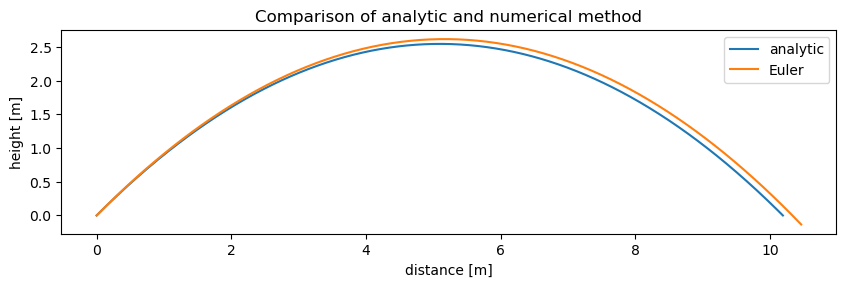

In [9]:
# Calculate trajectory using analytic method
x_an, y_an = trajectory(v_launch, theta_launch)

# Calculate trajectory using Euler's method, without air resistance
dt    = 0.02   # time step [s]
t_max = 10     # max time to simulate [s]
x_eul, y_eul = trajectory_euler(v_launch,theta_launch,dt,t_max)

# Plot trajectory
plt.figure()
plt.title("Comparison of analytic and numerical method")
plot_trajectory(x_an,y_an,'analytic')
plot_trajectory(x_eul,y_eul,'Euler')
plt.legend();

#code adapt from unit8notes

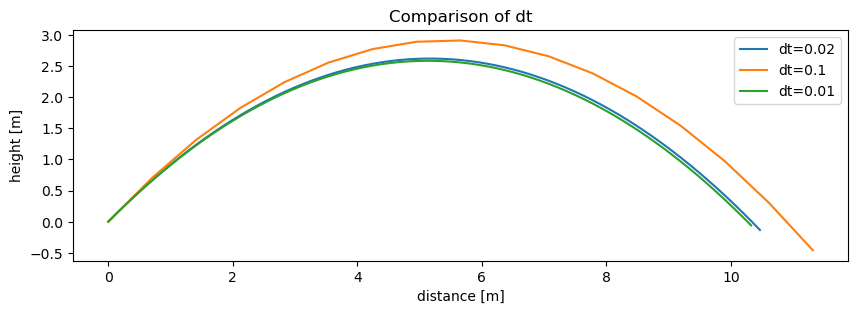

In [10]:
plt.figure()
plt.title("Comparison of dt")
x_eul, y_eul = trajectory_euler(v_launch,theta_launch,0.02,t_max)
plot_trajectory(x_eul,y_eul,'dt=0.02')
x_eul, y_eul = trajectory_euler(v_launch,theta_launch,0.1,t_max)
plot_trajectory(x_eul,y_eul,'dt=0.1')
x_eul, y_eul = trajectory_euler(v_launch,theta_launch,0.01,t_max)
plot_trajectory(x_eul,y_eul,'dt=0.01')
plt.legend();

as the value of dt increase, the plot become more unrealistic because the Euler's method assume every path in time interval dt is a straight line, but this is a parabola, therefore we need a smaller dt. I prefer dt=0.01 because it is precise enough and the code run fast, if we choose smaller dt, such as 0.001, the computer may take too many time on plotting graph, and the increase in precision of the plot is negligible.

In [11]:
def ar_move_projectile(position, velocity, dt,k):
    """
    Update the position and velocity of a projectile after an additional time step dt.

    Position and velocity are both 2-element arrays representing 2D vectors.
    """
    accel = -np.array([0,G])-velocity*k*np.linalg.norm(velocity)
    pos_new = position + velocity * dt    # updare position
    vel_new = velocity + accel    * dt    # update velocity
    return pos_new, vel_new

#code adapt from unit8notes

In [12]:
def ar_trajectory_euler(v0, angle, dt, t_max,k):
    """
    Calculate trajectory of projectile launched from the origin at given angle and speed,
    stopping when the projectile reaches the ground, or when a time limit is reached if
    this is earlier.
    
    Arguments:
        v0:    launch speed [m/s]
        angle: launch angle from horizontal [degrees]
        dt:    time step [s]
        t_max: maximum end time of calculation [s]
        k:     drag factor [1/m]
    
    Returns: NumPy arrays of coordinates x_array, y_array [m]
    """
    theta = np.radians(angle)

    # Set initial state of projectile
    t = 0.
    position = np.array([0., 0.])
    velocity = v0 * np.array([np.cos(theta), np.sin(theta)])
    x, y = position

    # Initialize lists of coordinate values, to which updated coords will be appended
    x_arr, y_arr = [x], [y]
    
    # Add points until the trajectory hits the ground or max time is reached
    while y>=0 and t < t_max:
        t += dt
        position, velocity = ar_move_projectile(position, velocity, dt,k) # update position and velocity
        x, y = position
        x_arr.append(x)
        y_arr.append(y)

    return np.array(x_arr), np.array(y_arr)

#code adapt from unit8notes

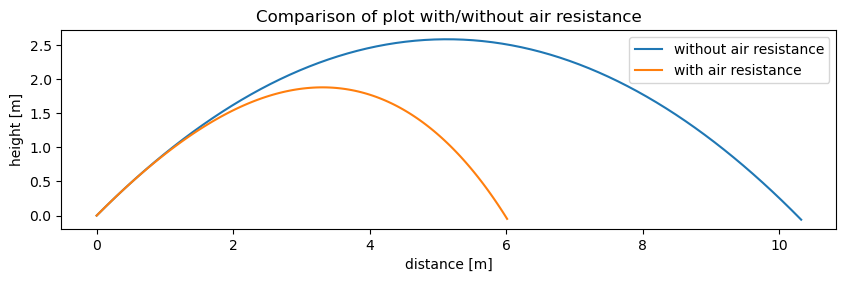

In [13]:
# Calculate trajectory using Euler's method, with/without air resistance
dt    = 0.01
t_max = 10
k=0.1
x_eul, y_eul = trajectory_euler(v_launch,theta_launch,dt,t_max)
x_eul_ar, y_eul_ar = ar_trajectory_euler(v_launch,theta_launch,dt,t_max,k)

# Plot trajectory
plt.figure()
plt.title("Comparison of plot with/without air resistance")
plot_trajectory(x_eul,y_eul,'without air resistance')
plot_trajectory(x_eul_ar,y_eul_ar,'with air resistance')
plt.legend();

the larger the k, the shorter the distance travelled. both maximum height and horizontal distance travelled decrease

## Conclusion

when there is a air resistance, both maximum height and horizontal distance travelled decrease because the air resistance is always opposite to the direction of the motion.

I think Euler's method is a good method when finding the differences with different value of k because it's calculation of path is easier than analytic method. But it is not a good method when making precise graph unless use extremelly small value of dt and wait for a long time.

## Reference

1. Unit8Notes